In [ ]:

import os
import requests

print("1. Stopping old downloads and cleaning up...")
!rm -f dataset.h5 train_nominal.h5 test_nominal.h5 test.h5 train.tmp test.tmp

print("2. Installing CERN's high-speed XRootD client...")
!apt-get update -qq
!apt-get install -y -qq xrootd-client

print("\n3. Locating the 7.6GB file via CERN API...")
res = requests.get("http://opendata.cern.ch/api/records/15013")
files = res.json()['metadata']['_files']

# Find the exact URI for the test file (which uses the root:// protocol)
test_uri = next(f['uri'] for f in files if 'test' in f['key'].lower())

print(f"Found URI: {test_uri}")

print("\n4. Downloading via XRootD (Grid Speeds)...")
# xrdcp bypasses the HTTP throttle and downloads at maximum Colab bandwidth
!xrdcp -f {test_uri} dataset.h5

!pip install -q h5py
print("\nSuccess! Fast download complete.")

1. Stopping old downloads and cleaning up...
2. Installing CERN's high-speed XRootD client...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)

3. Locating the 7.6GB file via CERN API...
Found URI: root://eospublic.cern.ch//eos/opendata/atlas/datascience/ATL-PHYS-PUB-2022-039/test.h5

4. Downloading via XRootD (Grid Speeds)...
[7.598GB/7.598GB][100%][==================================================][10.49MB/s]  

Success! Fast download complete.


In [ ]:
print("Current files in the directory:")
!ls -lh

Current files in the directory:
total 4.0K
drwxr-xr-x 1 root root 4.0K Jun  4 13:39 sample_data


In [ ]:
import h5py
import numpy as np
import torch
from torch import nn
from torch.utils.data import IterableDataset, DataLoader

class ColabTopTaggingDataset(IterableDataset):
    def __init__(self, h5_filepath, start_idx=0, end_idx=None, max_particles=80, chunk_size=2048):
        super().__init__()
        self.h5_filepath = h5_filepath
        self.max_particles = max_particles
        self.chunk_size = chunk_size
        self.start_idx = start_idx

        with h5py.File(self.h5_filepath, 'r') as f:
            total_jets = len(f['labels'])
            self.end_idx = end_idx if end_idx is not None else total_jets
            self.end_idx = min(self.end_idx, total_jets)

    def __iter__(self):
        with h5py.File(self.h5_filepath, 'r') as f:
            pt = f['fjet_clus_pt']
            eta = f['fjet_clus_eta']
            phi = f['fjet_clus_phi']
            energy = f['fjet_clus_E']
            labels = f['labels']

            has_weights = 'training_weights' in f.keys()
            weights = f['training_weights'] if has_weights else None

            for chunk_start in range(self.start_idx, self.end_idx, self.chunk_size):
                chunk_end = min(chunk_start + self.chunk_size, self.end_idx)

                c_pt = pt[chunk_start:chunk_end, :self.max_particles]
                c_eta = eta[chunk_start:chunk_end, :self.max_particles]
                c_phi = phi[chunk_start:chunk_end, :self.max_particles]
                c_e = energy[chunk_start:chunk_end, :self.max_particles]

                # --- KRİTİK DÜZELTME: Veri Ölçekleme ---
                # MeV cinsinden olan devasa pT ve E değerlerini logaritmik olarak küçültüyoruz
                # np.log1p (log(1+x)) kullanıyoruz ki sıfır dolgular (padding) bozulmasın
                c_pt = np.log1p(c_pt)
                c_e = np.log1p(c_e)

                # --- YENİ: FİZİKSEL MERKEZLEME (Shifting) ---
                # En yüksek pT'ye sahip parçacık 0. indekstedir. Onun eta ve phi
                # değerlerini jetin içindeki tüm parçacıklardan çıkarıyoruz.
                c_eta = c_eta - c_eta[:, 0:1]

                # Phi açısı dairesel olduğu için -pi ile +pi arasına sıkıştırıyoruz
                shifted_phi = c_phi - c_phi[:, 0:1]
                c_phi = np.mod(shifted_phi + np.pi, 2 * np.pi) - np.pi
                # ---------------------------------------

                c_labels = labels[chunk_start:chunk_end]
                c_weights = weights[chunk_start:chunk_end] if has_weights else np.ones(chunk_end - chunk_start)

                for i in range(chunk_end - chunk_start):
                    jet_matrix = np.column_stack((c_pt[i], c_eta[i], c_phi[i], c_e[i]))
                    yield (torch.tensor(jet_matrix, dtype=torch.float32),
                           torch.tensor(c_labels[i], dtype=torch.float32),
                           torch.tensor(c_weights[i], dtype=torch.float32))

In [ ]:
class ParticleFlowNetwork(nn.Module):
    def __init__(self, input_features=4, phi_sizes=(128, 256, 256), f_sizes=(256, 128)):
        super().__init__()

        # 1. The Phi Network (Applied to each particle independently)
        self.phi = nn.Sequential(
            nn.Conv1d(input_features, phi_sizes[0], kernel_size=1),
            nn.ReLU(),
            nn.Conv1d(phi_sizes[0], phi_sizes[1], kernel_size=1),
            nn.ReLU(),
            nn.Conv1d(phi_sizes[1], phi_sizes[2], kernel_size=1),
            nn.ReLU()
        )

        # 2. The F Network (Applied to the summed jet)
        self.f = nn.Sequential(
            nn.Linear(phi_sizes[2], f_sizes[0]),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(f_sizes[0], f_sizes[1]),
            nn.ReLU(),
            nn.Linear(f_sizes[1], 1) # Single output for binary classification
        )

    def forward(self, x):
        # Create a mask to ignore zero-padded particles (if pT > 0, it is a real particle)
        mask = (x[:, :, 0] > 0).float().unsqueeze(2)

        # PyTorch Conv1d expects shape: (batch_size, features, max_particles)
        x = x.transpose(1, 2)

        # Pass through Phi
        phi_out = self.phi(x)

        # Transpose back to apply mask: (batch, particles, 128)
        phi_out = phi_out.transpose(1, 2)
        phi_out = phi_out * mask

        # Sum pooling across the particle dimension
        jet_representation = torch.sum(phi_out, dim=1)

        # Pass through F to get the final prediction logit
        out = self.f(jet_representation)

        return out.squeeze()

In [ ]:
import torch.nn.functional as F
import torch.optim as optim
from torch.optim.lr_scheduler import StepLR
import time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training on: {device}")

model = ParticleFlowNetwork().to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001)

# YENİ: Her 2 epoch'ta bir öğrenme hızını (lr) %50 oranında (gamma=0.5) düşürür
scheduler = StepLR(optimizer, step_size=2, gamma=0.5)

train_dataset = ColabTopTaggingDataset('dataset.h5', start_idx=0, end_idx=2000000, max_particles=80)
train_loader = DataLoader(train_dataset, batch_size=512)

epochs = 5  # YENİ: 1 Epoch yerine 5 Epoch eğitim

model.train()
for epoch in range(epochs):
    start_time = time.time()
    running_loss = 0.0

    for batch_idx, (x, y, w) in enumerate(train_loader):
        x, y, w = x.to(device), y.to(device), w.to(device)

        optimizer.zero_grad()
        outputs = model(x)

        loss = F.binary_cross_entropy_with_logits(outputs, y, weight=w)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        if batch_idx % 100 == 0:
            print(f"Epoch [{epoch+1}/{epochs}] Batch {batch_idx} | Loss: {loss.item():.4f}")

    # YENİ: Epoch bittiğinde scheduler'a haber ver, gerekirse vites küçültsün
    scheduler.step()
    current_lr = scheduler.get_last_lr()[0]

    print(f"Epoch {epoch+1} Complete | Avg Loss: {running_loss/(batch_idx+1):.4f} | New LR: {current_lr:.5f} | Time: {time.time() - start_time:.1f}s")

torch.save(model.state_dict(), "pfn_top_tagger.pth")
print("Model saved to pfn_top_tagger.pth")

Training on: cuda
Epoch [1/5] Batch 0 | Loss: 1.3449
Epoch [1/5] Batch 100 | Loss: 0.6920
Epoch [1/5] Batch 200 | Loss: 0.6590
Epoch [1/5] Batch 300 | Loss: 0.6037
Epoch [1/5] Batch 400 | Loss: 0.6143
Epoch [1/5] Batch 500 | Loss: 0.5920
Epoch [1/5] Batch 600 | Loss: 0.6243
Epoch [1/5] Batch 700 | Loss: 0.5815
Epoch [1/5] Batch 800 | Loss: 0.5665
Epoch [1/5] Batch 900 | Loss: 0.5186
Epoch [1/5] Batch 1000 | Loss: 0.5473
Epoch [1/5] Batch 1100 | Loss: 0.5051
Epoch [1/5] Batch 1200 | Loss: 0.5626
Epoch [1/5] Batch 1300 | Loss: 0.5441
Epoch [1/5] Batch 1400 | Loss: 0.4905
Epoch [1/5] Batch 1500 | Loss: 0.4865
Epoch [1/5] Batch 1600 | Loss: 0.6127
Epoch [1/5] Batch 1700 | Loss: 0.5028
Epoch [1/5] Batch 1800 | Loss: 0.5130
Epoch [1/5] Batch 1900 | Loss: 0.5307
Epoch [1/5] Batch 2000 | Loss: 0.5013
Epoch [1/5] Batch 2100 | Loss: 0.4991
Epoch [1/5] Batch 2200 | Loss: 0.4905
Epoch [1/5] Batch 2300 | Loss: 0.4873
Epoch [1/5] Batch 2400 | Loss: 0.4887
Epoch [1/5] Batch 2500 | Loss: 0.4338
Epoch 

Running inference on test set (This will take a minute)...

Test AUC: 0.9444
Optimal Threshold: 0.5150

Classification Report:
              precision    recall  f1-score   support

  Background       0.87      0.86      0.87    242030
  Top Signal       0.87      0.88      0.87    242087

    accuracy                           0.87    484117
   macro avg       0.87      0.87      0.87    484117
weighted avg       0.87      0.87      0.87    484117



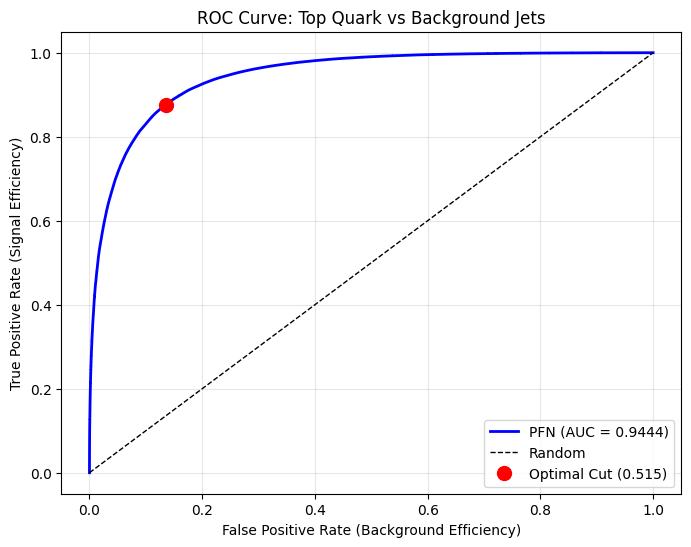

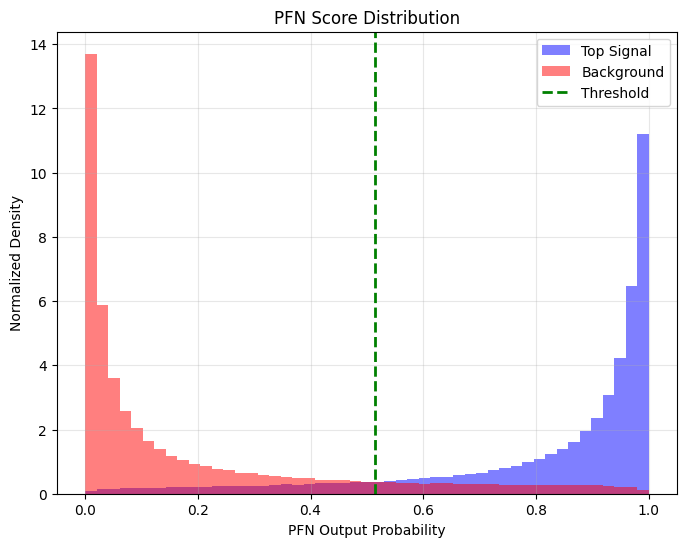

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, classification_report

# Use everything from index 2,000,000 onward for testing
test_dataset = ColabTopTaggingDataset('dataset.h5', start_idx=2000000, max_particles=80)
test_loader = DataLoader(test_dataset, batch_size=1024)

model.eval()
all_preds = []
all_labels = []

print("Running inference on test set (This will take a minute)...")
with torch.no_grad():
    for x, y, _ in test_loader:
        x = x.to(device)
        logits = model(x)
        probs = torch.sigmoid(logits)

        all_preds.extend(probs.cpu().numpy())
        all_labels.extend(y.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

auc_score = roc_auc_score(all_labels, all_preds)
print(f"\nTest AUC: {auc_score:.4f}")

fpr, tpr, thresholds = roc_curve(all_labels, all_preds)
j_scores = tpr - fpr
best_idx = np.argmax(j_scores)
optimal_threshold = thresholds[best_idx]
print(f"Optimal Threshold: {optimal_threshold:.4f}")

y_pred_optimal = (all_preds >= optimal_threshold).astype(int)
print("\nClassification Report:")
print(classification_report(all_labels, y_pred_optimal, target_names=["Background", "Top Signal"]))

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(fpr, tpr, 'b-', lw=2, label=f'PFN (AUC = {auc_score:.4f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random')
ax.plot(fpr[best_idx], tpr[best_idx], 'ro', ms=10, label=f'Optimal Cut ({optimal_threshold:.3f})')
ax.set_xlabel('False Positive Rate (Background Efficiency)')
ax.set_ylabel('True Positive Rate (Signal Efficiency)')
ax.set_title('ROC Curve: Top Quark vs Background Jets')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
bins = np.linspace(0, 1, 50)
ax.hist(all_preds[all_labels == 1], bins=bins, density=True, histtype='stepfilled', alpha=0.5, color='blue', label='Top Signal')
ax.hist(all_preds[all_labels == 0], bins=bins, density=True, histtype='stepfilled', alpha=0.5, color='red', label='Background')
ax.axvline(optimal_threshold, color='green', ls='--', lw=2, label='Threshold')
ax.set_xlabel('PFN Output Probability')
ax.set_ylabel('Normalized Density')
ax.set_title('PFN Score Distribution')
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()